<a href="https://colab.research.google.com/github/sasikumaar1006/Retinal_disease_detection/blob/main/notebooks/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install datasets matplotlib numpy pandas -q

from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [3]:
ds = load_dataset("zacharielegault/Kermany2017-OCT")
print(ds)
print(len(ds['train']))
print(len(ds['test']))

README.md:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

data/train-00000-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  369MB            

data/train-00000-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  473MB            

data/train-00001-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  462MB            

... (28 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/108309 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 108309
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1000
    })
})
108309
1000


In [4]:
train_data = ds["train"]
test_data = ds["test"]

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print(train_data.features)

Training samples: 108309
Testing samples: 1000
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'DRUSEN', 'NORMAL'])}


Label: 0
Image size: (512, 496)
Image mode: L


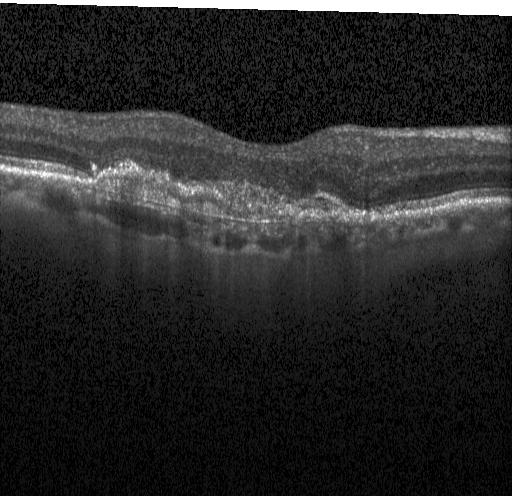

In [5]:
sample1 = train_data[0]

image = sample1["image"]
label = sample1["label"]

print("Label:", label)
print("Image size:", image.size)
print("Image mode:", image.mode)

display(image)

Dataset features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'DRUSEN', 'NORMAL'])}
Class names mapping: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Class 'CNV': 37205 images
Class 'DME': 11348 images
Class 'DRUSEN': 8616 images
Class 'NORMAL': 51140 images


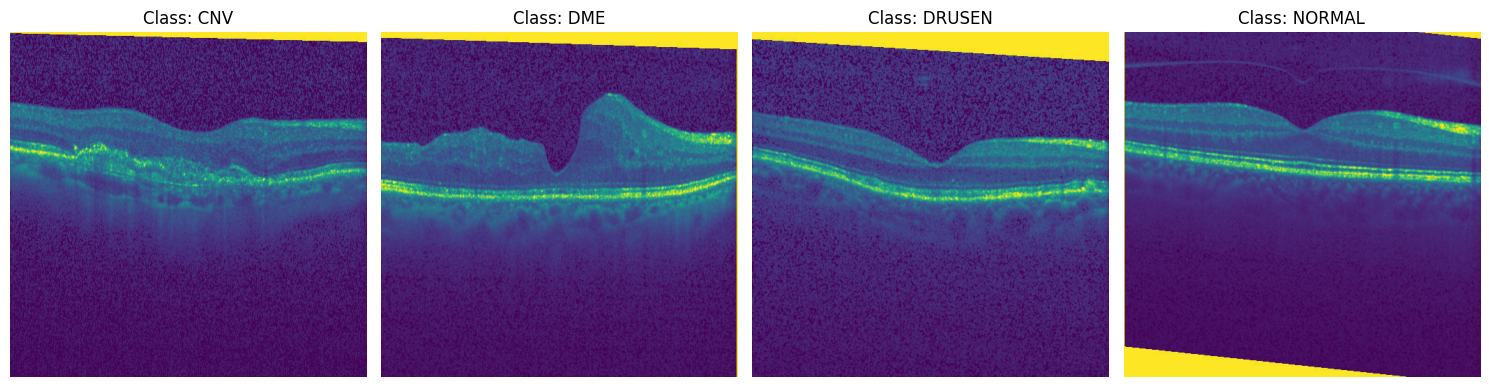

In [ ]:
import collections

# Inspect the features and labels of the training dataset
features = train_data.features
print("Dataset features:", features)

# Number of samples exist per class label in the training set
labels = train_data['label']
class_names = features['label'].names
print("Class names mapping:", class_names)

counter = collections.Counter(labels)
for idx, count in sorted(counter.items()):
    print(f"Class '{class_names[idx]}': {count} images")

# Plot one sample image from each class
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
for i, class_name in enumerate(class_names):
    # Find the first index matching this class label in the training set
    idx = labels.index(i)
    sample = train_data[idx]

    axes[i].imshow(sample['image'])
    axes[i].set_title(f"Class: {class_name}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [7]:
# Checking shape of a few sample images
for i in range(3):
    img = train_data[i]['image']
    print(f"Image {i} size (Width, Height): {img.size}, Mode: {img.mode}")

Image 0 size (Width, Height): (512, 496), Mode: L
Image 1 size (Width, Height): (768, 496), Mode: L
Image 2 size (Width, Height): (1536, 496), Mode: L


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Defining distinct transforms
# Data augmentation like RandomHorizontalFlip ONLY to training set
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Test/Validation transform
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [10]:
class OCTDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item['image'].convert("RGB")
        label = item['label']

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

# Creating strictly separated datasets and data loaders to prevent data leakage
train_dataset = OCTDataset(train_data, transform=train_transform)
test_dataset = OCTDataset(test_data, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False) # shuffle=False for testing

print(f"Train DataLoader batches: {len(train_loader)}")
print(f"Test DataLoader batches: {len(test_loader)}")

Train DataLoader batches: 3385
Test DataLoader batches: 32


In [12]:
# Fetching one single batch from the train loader to inspect shapes
images, labels = next(iter(train_loader))

print("--- Individual Transformed Item Check ---")
print("Single image tensor shape :", images[0].shape)
print("Single image min/max value:", images[0].min().item(), "/", images[0].max().item())
print("Corresponding label tensor  :", labels[0])
print("Corresponding label value   :", labels[0].item())

# Also verifying test loader item shape
test_images, test_labels = next(iter(test_loader))
print("\n--- Test Batch Check ---")
print("Test images batch shape   :", test_images.shape)
print("Test labels batch shape   :", test_labels.shape)

--- Individual Transformed Item Check ---
Single image tensor shape : torch.Size([3, 224, 224])
Single image min/max value: -2.1179039478302 / 2.640000104904175
Corresponding label tensor  : tensor(3)
Corresponding label value   : 3

--- Test Batch Check ---
Test images batch shape   : torch.Size([32, 3, 224, 224])
Test labels batch shape   : torch.Size([32])
